# Normalize Datasets 1 + 2, Encode Dataset 2, Save

In [ ]:

import pandas as pd
df = pd.read_csv('project1_dataset1.txt', sep='\t', header=None)
df_2 = pd.read_csv('project1_dataset2.txt', sep='\t', header=None)

In [17]:
# print(df.head())
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
normalized_array = scaler.fit_transform(df)
df_normalized = pd.DataFrame(normalized_array, columns=df.columns)

df_2[4] = df_2[4].map({'Present': 1, 'Absent': 0})
normalized_array_2 = scaler.fit_transform(df_2)
df_normalized_2 = pd.DataFrame(normalized_array_2, columns=df_2.columns)

In [ ]:
df_normalized.to_csv('data_1_normalized.csv', index=False)
df_normalized_2.to_csv('data_2_normalized.csv', index=False)

# Dataset 1 - Nearest Neighbor, Decision Tree, Naive Bayes, SVM

**KNN 1**

accuracy: 98.84%


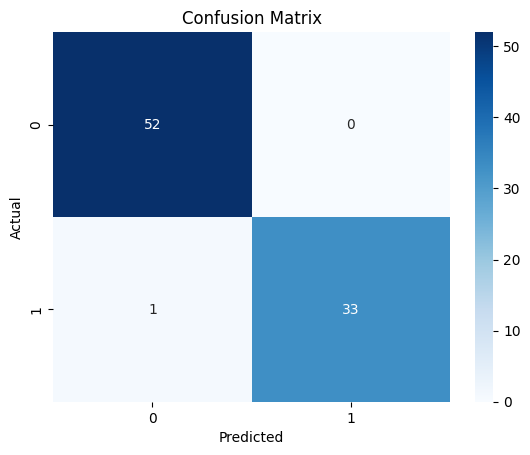

In [158]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data_1_normalized.csv")
X = df.drop(df.columns[30], axis=1)
y = df[df.columns[30]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)

scaler = StandardScaler() # scale features just in case
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train_scaled, y_train)

accuracy = knn.score(X_test_scaled, y_test)
print(f"accuracy: {accuracy * 100:.2f}%")

import seaborn as sns
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
cm=confusion_matrix(y_test, knn.predict(X_test_scaled))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# combinations tried:
# -> test=0.2, nn=5, accuracy = 97.37
# -> test=0.1, nn=5, accuracy = 98.25
# -> test=0.15, nn=5, accuracy = 97.67
# -> test=0.15, nn=10, accuracy = 98.84 ***
# -> test=.1, nn=20, accuracy = 96.49

**Decision Tree 1**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv("data_1_normalized.csv")
X = df.drop(df.columns[30], axis=1)
y = df[df.columns[30]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13)

clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=13)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"accuracy: {accuracy * 100:.2f}%\n")

# confusion matrix (just to check if overfitting)
# import seaborn as sns
# from sklearn.metrics import confusion_matrix
# cm = confusion_matrix(y_test, y_pred)
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
# plt.title('Confusion Matrix')
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.show()

# tried: 
# test=0.2, max_depth=3, acc=95.61 *** 
# test=0.15, max_depth=3, acc=94.19
# test=0.2, max_depth=10, acc=93.86

accuracy: 95.61%



**Naive Bayes 1**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

df = pd.read_csv("data_1_normalized.csv")
X = df.drop(df.columns[30], axis=1)
y = df[df.columns[30]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)
model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"accuracy: {accuracy * 100:.2f}%\n")

# confusion matrix (just to check if overfitting)
# import seaborn as sns
# from sklearn.metrics import confusion_matrix
# cm = confusion_matrix(y_test, y_pred)
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
# plt.title('Confusion Matrix')
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.show()

# tried: 
# test=0.2, acc=93.86  
# test=0.15, acc=95.35 ***
# test=0.25, acc=95.10
# test=0.3, acc=94.15

accuracy: 95.35%



**SVM 1**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

df = pd.read_csv("data_1_normalized.csv")
X = df.drop(df.columns[30], axis=1)
y = df[df.columns[30]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=13)

scaler = StandardScaler() # scale just in case like in NN
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_classifier = SVC(kernel='rbf', C=1, gamma='scale', random_state=13)
svm_classifier.fit(X_train_scaled, y_train)
y_pred = svm_classifier.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}\n")

# tried: 
# rbf kernel, C=1, gamma=scale, test=.2, acc=97.37 ***
# poly kernel, C=1, gamma=scale, test=.2, acc=87.72
# linear kernel, C=1, gamma=scale, test=.2, acc=97.37
# linear kernel, C=0.5, gamma=scale, test=.2, acc=96.49
# rbf kernel, C=.3, gamma=scale, test=.2, acc=97.37 (why is this not changed?)

Accuracy Score: 0.9737



# Dataset 2 - Nearest Neighbor, Decision Tree, Naive Bayes, SVM

**KNN 2**

accuracy: 69.62%


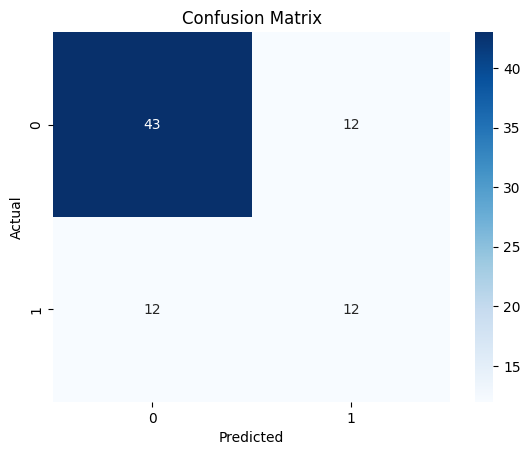

In [70]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data_2_normalized.csv")
X = df.drop(df.columns[9], axis=1)
y = df[df.columns[9]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.17, random_state=13)

scaler = StandardScaler() # scale features just in case
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

accuracy = knn.score(X_test_scaled, y_test)
print(f"accuracy: {accuracy * 100:.2f}%")

# confusion matrix (just to check if overfitting)
import seaborn as sns
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
cm=confusion_matrix(y_test, knn.predict(X_test_scaled))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# dataset 2 is more difficult, try to reduce tendency towards predicting class 1

# combinations tried:
# -> test=0.15, nn=10, accuracy = 69.86 ***
# -> test=0.25, nn=5, accuracy = 69.83 
# -> test=0.17, nn=5, accuracy = 69.62 
# -> test=0.2, nn=5, accuracy = 68.82
# -> test=0.1, nn=5, accuracy = 65.96
# -> test=0.15, nn=5, accuracy = 65.71
# -> test=.1, nn=20, accuracy = 68.09

**Decision Tree 2**

In [85]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv("data_2_normalized.csv")
X = df.drop(df.columns[9], axis=1)
y = df[df.columns[9]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)

clf = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=13)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"accuracy: {accuracy * 100:.2f}%\n")

# confusion matrix (just to check if overfitting)
# import seaborn as sns
# from sklearn.metrics import confusion_matrix
# cm = confusion_matrix(y_test, y_pred)
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
# plt.title('Confusion Matrix')
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.show()

# tried: 
# gini, test=0.2, max_depth=3, acc=60.22  
# gini, test=0.15, max_depth=3, acc=64.29 
# entropy, test=0.2, max_depth=5, acc=62.37 
# entropy, test=0.2, max_depth=3, acc=60.22 
# entropy, test=0.15, max_depth=3, acc=64.29 *** (less lean towards class 1 tho)

accuracy: 64.29%



**Naive Bayes 2**

accuracy: 71.55%



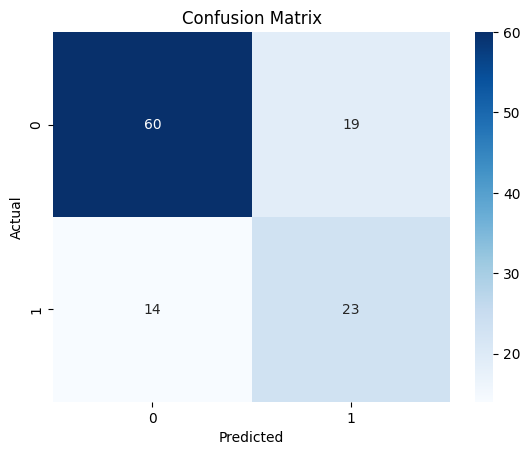

In [160]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

df = pd.read_csv("data_2_normalized.csv")
X = df.drop(df.columns[9], axis=1)
y = df[df.columns[9]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)
model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"accuracy: {accuracy * 100:.2f}%\n")

# confusion matrix (just to check if overfitting)
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# tried: 
# test=0.2, acc=67.74  
# test=0.15, acc=68.57 
# test=0.25, acc=71.55 ***
# test=0.3, acc=71.22

**SVM 2**

Accuracy Score: 0.7241



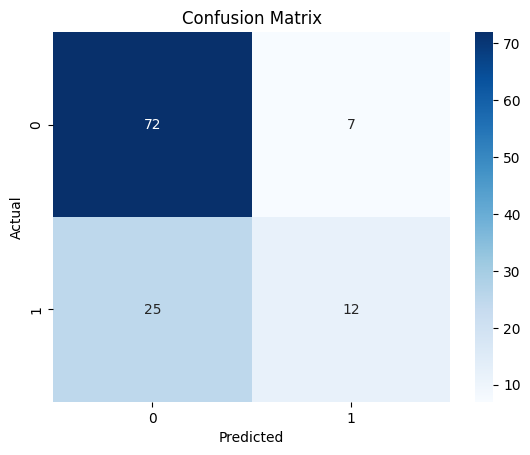

In [159]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

df = pd.read_csv("data_2_normalized.csv")
X = df.drop(df.columns[9], axis=1)
y = df[df.columns[9]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)

scaler = StandardScaler() # scale just in case like in NN
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_classifier = SVC(kernel='poly', C=1, gamma='scale', random_state=13)
svm_classifier.fit(X_train_scaled, y_train)
y_pred = svm_classifier.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}\n")

# show confusion matrix (just to check if overfitting)
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# tried: 
# rbf kernel, C=1, test=.2, acc=68.82
# poly kernel, C=1, test=.2, acc=70.97
# poly kernel, C=1, test=.25, acc=72.41
# linear kernel, C=1, test=.2, acc=70.97
# linear kernel, C=0.5, test=.2, acc=70.97
# rbf kernel, C=.3, test=.2, acc=66.67

# AdaBoost

**AdaBoost 1**

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

df = pd.read_csv("data_1_normalized.csv")
X = df.drop(df.columns[30], axis=1)
y = df[df.columns[30]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13)
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=13)

adaboost_clf = AdaBoostClassifier(estimator=clf, n_estimators=50, learning_rate=0.2, random_state=13)
adaboost_clf.fit(X_train, y_train)

predictions = adaboost_clf.predict(X_test)
print(f"AdaBoost Accuracy: {accuracy_score(y_test, predictions):.2f}")

# tested
# n=100, l=.1
# n=50, l=.1
# n=50, l=.2 ***
# n=40, l=.2

AdaBoost Accuracy: 0.96


In [114]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

df = pd.read_csv("data_2_normalized.csv")
X = df.drop(df.columns[9], axis=1)
y = df[df.columns[9]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)
clf = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=13)

adaboost_clf = AdaBoostClassifier(estimator=clf, n_estimators=60, learning_rate=0.15, random_state=13)
adaboost_clf.fit(X_train, y_train)

predictions = adaboost_clf.predict(X_test)
print(f"AdaBoost Accuracy: {accuracy_score(y_test, predictions):.2f}")

# tested 
# n=100, l=.1 -> 69
# n=50, l=.1 -> 67
# n=50, l=.2 -> 69
# n=40, l=.2 -> 67
# n=60, l=.15 -> 70 ***

AdaBoost Accuracy: 0.70


# Neural Net

In [116]:
!pip install torch

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.3/127.3 MB 17.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 16.9 MB/s eta 0:00:00a 0:00:01
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [torch]32m4/5 [torch]


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
 
class TorchNN(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden=16, dropout=0.25, lr=1e-3, weight_decay=1e-2, epochs=150):
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.epochs = epochs
 
    def fit(self, X, y):
        torch.manual_seed(13)
        self.classes_ = np.unique(y)
        X_t = torch.tensor(np.asarray(X), dtype=torch.float32)
        y_t = torch.tensor((np.asarray(y) == self.classes_[1]), dtype=torch.float32)
 
        # small network + dropout + weight decay
        # small dataset keep regularized
        self.model_ = nn.Sequential(
            nn.Linear(X_t.shape[1], self.hidden), nn.ReLU(), nn.Dropout(self.dropout),
            nn.Linear(self.hidden, 1),
        )
        criterion = nn.BCEWithLogitsLoss()
        optimizer = torch.optim.AdamW(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
 
        # full-batch training
        for epoch in range(self.epochs):
            self.model_.train()
            optimizer.zero_grad()
            loss = criterion(self.model_(X_t).squeeze(1), y_t)
            loss.backward()
            optimizer.step()
        return self
 
    def predict(self, X):
        self.model_.eval()
        with torch.no_grad():
            logits = self.model_(torch.tensor(np.asarray(X), dtype=torch.float32)).squeeze(1)
        return self.classes_[(torch.sigmoid(logits) > 0.5).numpy().astype(int)]
 
 
df = pd.read_csv("data_1_normalized.csv")
X = df.drop(df.columns[30], axis=1)
y = df[df.columns[30]]
 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)
 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
 
model_nn = TorchNN(hidden=16, dropout=0.25, lr=1e-3, weight_decay=1e-2, epochs=150)
model_nn.fit(X_train_scaled, y_train)
 
accuracy = model_nn.score(X_test_scaled, y_test)
print(f"accuracy: {accuracy * 100:.2f}%")


accuracy: 98.84%


In [156]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
 
class TorchNN(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden=16, dropout=0.2, lr=1e-2, weight_decay=1e-2, epochs=50):
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.epochs = epochs
 
    def fit(self, X, y):
        torch.manual_seed(13)
        self.classes_ = np.unique(y)
        X_t = torch.tensor(np.asarray(X), dtype=torch.float32)
        y_t = torch.tensor((np.asarray(y) == self.classes_[1]), dtype=torch.float32)
 
        self.model_ = nn.Sequential(
            nn.Linear(X_t.shape[1], self.hidden), nn.ReLU(), nn.Dropout(self.dropout),
            nn.Linear(self.hidden, 1),
        )
 
        # weight the positive class (1) up so discourage just predicting class 0
        n_pos = y_t.sum()
        n_neg = len(y_t) - n_pos
        criterion = nn.BCEWithLogitsLoss(pos_weight=n_neg / n_pos)
        optimizer = torch.optim.AdamW(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
 
        for epoch in range(self.epochs):
            self.model_.train()
            optimizer.zero_grad()
            loss = criterion(self.model_(X_t).squeeze(1), y_t)
            loss.backward()
            optimizer.step()
        return self
 
    def predict(self, X):
        self.model_.eval()
        with torch.no_grad():
            logits = self.model_(torch.tensor(np.asarray(X), dtype=torch.float32)).squeeze(1)
        return self.classes_[(torch.sigmoid(logits) > 0.5).numpy().astype(int)]
 
 
df = pd.read_csv("data_2_normalized.csv")
X = df.drop(df.columns[9], axis=1)
y = df[df.columns[9]]
 
# stratify -> class ratio the same in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13, stratify=y)
 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
 
model = TorchNN(hidden=16, dropout=0.2, lr=1e-2, weight_decay=1e-2, epochs=50)
model.fit(X_train_scaled, y_train)
 
accuracy = model.score(X_test_scaled, y_test)
print(f"accuracy: {accuracy * 100:.2f}%")


accuracy: 80.00%


# 10-Fold Cross Val 

**Cross Validation 1**

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
 
df = pd.read_csv("data_1_normalized.csv")
X = df.drop(df.columns[30], axis=1)
y = df[df.columns[30]]

#nearest neighbor
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
knn = KNeighborsClassifier(n_neighbors=10)

# decision tree
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13)
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=13)

#naive bayes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)
model = GaussianNB()

#svm
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=13)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
svm_classifier = SVC(kernel='rbf', C=1, gamma='scale', random_state=13)

#adaboost
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13)
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=13)
adaboost_clf = AdaBoostClassifier(estimator=clf, n_estimators=50, learning_rate=0.2, random_state=13)

#neural net

models = {
    "Nearest Neighbor": knn,
    "Decision Tree": clf,
    "Naive Bayes": model,
    "SVM": svm_classifier,
    "AdaBoost": adaboost_clf,
    "Neural Network": model_nn,
}
 
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision_macro",
    "Recall": "recall_macro",
    "F1": "f1_macro",
}
 
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=13)
 
rows = []
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        **{m: scores[f"test_{m}"].mean() for m in scoring},
    })
 
results = pd.DataFrame(rows).set_index("Model")
print((results * 100).round(2).to_string())


                  Accuracy  Precision  Recall     F1
Model                                               
Nearest Neighbor     96.30      97.00   95.26  95.95
Decision Tree        91.74      91.51   90.94  91.11
Naive Bayes          93.14      93.26   92.34  92.62
SVM                  97.19      97.19   96.91  96.98
AdaBoost             95.78      95.92   95.20  95.45
Neural Network       96.66      96.75   96.19  96.39


In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
 
df = pd.read_csv("data_2_normalized.csv")
X = df.drop(df.columns[9], axis=1)
y = df[df.columns[9]]

#nearest neighbor
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.17, random_state=13)
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
knn = KNeighborsClassifier(n_neighbors=5)

# decision tree
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)
clf = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=13)

#naive bayes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)
model = GaussianNB()

#svm
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
svm_classifier = SVC(kernel='poly', C=1, gamma='scale', random_state=13)

#adaboost
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=13)
clf = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=13)
adaboost_clf = AdaBoostClassifier(estimator=clf, n_estimators=60, learning_rate=0.15, random_state=13)

#neural net

models = {
    "Nearest Neighbor": knn,
    "Decision Tree": clf,
    "Naive Bayes": model,
    "SVM": svm_classifier,
    "AdaBoost": adaboost_clf,
    "Neural Network": model,
}
 
# macro averages the metric over classes (works for 2+ classes);
# use "binary" instead if you only care about the positive class
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision_macro",
    "Recall": "recall_macro",
    "F1": "f1_macro",
}
 
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=13)
 
rows = []
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        **{m: scores[f"test_{m}"].mean() for m in scoring},
    })
 
results = pd.DataFrame(rows).set_index("Model")
print((results * 100).round(2).to_string())
